Verificando se está no COLAB



In [24]:
try:
    import google.colab
    IN_COLAB = True
except:
    IN_COLAB = False

# DEBUG
print(IN_COLAB)

True


Packages necessarios para o codigo


In [25]:
import os
import random
import time
import platform
import shutil
import copy
import pandas as pd

import numpy as np
import matplotlib.pyplot as plt
from sklearn import metrics
from sklearn.model_selection import train_test_split

import torch
import torch.nn.functional as F
from torch import nn, optim
# import torch.nn as nn
# import torch.optim as optim
from torch.optim import lr_scheduler

from torchvision import transforms, models, datasets, utils

Configurações para reprodutibilidade


In [26]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

In [27]:
# Verifica se a GPU está disponível
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('\nDevice: {0}'.format(DEVICE))


Device: cuda


Instânciando dataset


In [28]:
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

    # Copia o dataset do Drive para o disco local do Colab (muito mais rápido para ler)
    if not os.path.exists('/content/chest_xray'):
        shutil.copytree('/content/drive/My Drive/DATASET/chest_xray', '/content/chest_xray')

    ds_trainpath = '/content/chest_xray/train'
    ds_testpath = '/content/chest_xray/test'
else:
    ds_trainpath = './chest_xray/train'
    ds_testpath = './chest_xray/test'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [29]:
# Questão experimental secundária: efeito do desbalanceamento das classes.
# True  -> CrossEntropy com pesos inversamente proporcionais à frequência de cada classe
# False -> CrossEntropy sem pesos (baseline)
USE_CLASS_WEIGHTS = False

# Resultados: no Google Drive (Colab) ou na pasta ./resultados (execução local)
EXP_BASE = '/content/drive/My Drive/' if IN_COLAB else './resultados/'
EXP_PATH = EXP_BASE + 'exp-18-' + ('CE-pesos' if USE_CLASS_WEIGHTS else 'CE-sem-pesos') + '/'
if not os.path.exists(EXP_PATH):
    os.makedirs(EXP_PATH)
print(EXP_PATH)

/content/drive/My Drive/exp-18-CE-sem-pesos/


In [30]:
# Número de classes
num_classes = 2

# Nomes das classes
class_names = ['normal','pneumonia']

In [31]:
# Tamanho do lote
batch_size = 128
# Taxa de aprendizado
lr = 0.0005
# Mommentum
mm = 0.9
# Número de épocas
epochs = 25
# Step size
ss = 10

In [32]:
data_transforms_train = transforms.Compose([#Transform de treino, faz o resize
                                            #E também realza o data augmentation
    transforms.Resize((224, 224)),
    transforms.RandomAffine(degrees=7, translate=(0.05, 0.05), scale=(0.9, 1.1)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.08)),
])

data_transforms_test = transforms.Compose([# Necessário resimensionar as imagens para o tamanho da entrada da rede.
                                      # As radiografias possuem tamanhos diferentes.
                                      transforms.Resize(size=(224, 224)),
                                      transforms.ToTensor(),
                                      # Média e desvio padrão do ImageNet.
                                      # Pois utilizaremos um modelo pré-treinado com o ImageNet.
                                      transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
                                     ])


# Constrói um dataset a partir de uma pasta.
# Para isso, a pasta deve conter uma subpasta para cada classe do problema.
test_dataset = datasets.ImageFolder(ds_testpath,transform=data_transforms_test)
full_train_dataset = datasets.ImageFolder(ds_trainpath,transform=data_transforms_train)
full_val_dataset = datasets.ImageFolder(ds_trainpath, transform=data_transforms_test)

Divisão treino/validação por paciente

O conjunto de teste é a pasta `test` original do dataset. A pasta `val` original (16 imagens) não é usada. A pasta `train` é dividida em 80% treino e 20% validação **por paciente**: todas as imagens de um mesmo paciente ficam no mesmo conjunto, evitando vazamento de dados entre treino e validação.

In [33]:
# Conjunto de Teste:
test_size = len(test_dataset)

# 80/20 Treino/Validação - divisão POR PACIENTE
# Vários pacientes têm mais de uma radiografia (um deles tem 30). Se as imagens de um
# mesmo paciente caírem no treino e na validação, a validação fica otimista
# (vazamento de dados). Por isso, dividimos os PACIENTES com o train_test_split
# (estratificado, semente fixa) e depois levamos todas as imagens de cada paciente
# para o mesmo lado.
import re

def patient_id(path):
    # Extrai o identificador do paciente a partir do nome do arquivo:
    #   PNEUMONIA: person123_bacteria_456.jpeg -> person123
    #   NORMAL:    IM-0115-0001.jpeg           -> IM-0115
    #              NORMAL2-IM-0383-0001.jpeg   -> NORMAL2-IM-0383
    name = os.path.basename(path)
    m = re.match(r'(person\d+)_', name) or re.match(r'((?:NORMAL2-)?IM-\d+)-', name)
    return m.group(1) if m else name  # sem padrão: cada arquivo vira um paciente

patient_ids = np.array([patient_id(p) for p, _ in full_train_dataset.samples])
targets = np.array(full_train_dataset.targets)

# Classe de cada paciente (todas as imagens de um paciente têm a mesma classe)
patient_class = {}
for pid, t in zip(patient_ids, targets):
    assert patient_class.setdefault(pid, t) == t, f'Paciente {pid} com classes diferentes'
unique_patients = sorted(patient_class)

train_patients, val_patients = train_test_split(
    unique_patients,
    test_size=0.2,
    stratify=[patient_class[p] for p in unique_patients],
    random_state=SEED)

train_patients = set(train_patients)
train_idx = [i for i, pid in enumerate(patient_ids) if pid in train_patients]
val_idx = [i for i, pid in enumerate(patient_ids) if pid not in train_patients]

# Verificação: nenhum paciente pode aparecer nos dois conjuntos
assert set(patient_ids[train_idx]).isdisjoint(set(patient_ids[val_idx]))

print(f'Pacientes: {len(unique_patients)} no total | '
      f'{len(train_patients)} treino | {len(val_patients)} validação (nenhum em comum)')
for nome, idx in (('Treino', train_idx), ('Validação', val_idx)):
    c = np.bincount(targets[idx], minlength=num_classes)
    print(f'{nome}: {len(idx)} imagens | ' +
          ' | '.join(f'{class_names[k]}: {c[k]} ({c[k] / len(idx):.1%})' for k in range(num_classes)))
print()

train_dataset = torch.utils.data.Subset(full_train_dataset, train_idx)
val_dataset = torch.utils.data.Subset(full_val_dataset, val_idx)

test_dataset = test_dataset

# Número de imagens em cada dataset
train_size = len(train_dataset)
val_size = len(val_dataset)

print(train_size)
print(val_size)
print(test_size)

# Reprodutibilidade dos DataLoaders (ordem do shuffle e sementes dos workers)
def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

# Processos auxiliares para carregar as imagens: só no Colab (Linux).
# Em Windows, macOS e Python 3.14+, os processos auxiliares não enxergam funções
# definidas no notebook (como seed_worker) e o DataLoader falha. Localmente,
# as imagens são carregadas no processo principal (num_workers = 0).
NUM_WORKERS = 2 if IN_COLAB else 0
loader_kwargs = dict(batch_size=batch_size, num_workers=NUM_WORKERS,
                     pin_memory=torch.cuda.is_available(),
                     persistent_workers=NUM_WORKERS > 0)
if NUM_WORKERS > 0:
    loader_kwargs['worker_init_fn'] = seed_worker

g = torch.Generator()
g.manual_seed(SEED)

# Definindo os dataloaders
train_dataloader = torch.utils.data.DataLoader(dataset=train_dataset, shuffle=True, generator=g, **loader_kwargs)
val_dataloader = torch.utils.data.DataLoader(dataset=val_dataset, shuffle=False, **loader_kwargs)
test_dataloader = torch.utils.data.DataLoader(dataset=test_dataset, shuffle=False, **loader_kwargs)


Pacientes: 2846 no total | 2276 treino | 570 validação (nenhum em comum)
Treino: 4209 imagens | normal: 1077 (25.6%) | pneumonia: 3132 (74.4%)
Validação: 1007 imagens | normal: 264 (26.2%) | pneumonia: 743 (73.8%)

4209
1007
624


Pesos por classe (desbalanceamento: normal x pneumonia)

In [34]:
# Contagem de classes só no split de TREINO (80%), não no dataset inteiro
train_targets = [full_train_dataset.targets[i] for i in train_idx]
counts = np.bincount(train_targets)  # [n_normal, n_pneumonia]

# Peso inversamente proporcional à frequência
weights = len(train_targets) / (num_classes * counts)
class_weights = torch.tensor(weights, dtype=torch.float).to(DEVICE)

print('Contagem por classe (treino):', dict(zip(class_names, counts.tolist())))
print('Pesos por classe:', dict(zip(class_names, np.round(weights, 4).tolist())))

# Baseline sem pesos (experimento de desbalanceamento)
if not USE_CLASS_WEIGHTS:
    class_weights = None
    print('USE_CLASS_WEIGHTS = False -> treinando SEM pesos por classe')

Contagem por classe (treino): {'normal': 1077, 'pneumonia': 3132}
Pesos por classe: {'normal': 1.954, 'pneumonia': 0.6719}
USE_CLASS_WEIGHTS = False -> treinando SEM pesos por classe


In [35]:
# Fine-tuning
model_ft = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)

num_ftrs = model_ft.fc.in_features
model_ft.fc = nn.Linear(num_ftrs, num_classes)


In [36]:
model = model_ft

In [37]:
if DEVICE.type == 'cuda':
    model = model.cuda() # Cuda

# Imprime o modelo
print(str(model))

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Con

In [38]:
# Função de perda
criterion = nn.CrossEntropyLoss(weight=class_weights)  # pesos por classe (None = sem pesos)

# Otimizador
optimizer = optim.SGD(model.parameters(), lr=lr, momentum=mm)

# Adjust learning rate
scheduler = lr_scheduler.StepLR(optimizer, step_size=ss)

In [39]:
# Tempo total do treinamento (treinamento e validação)
time_total_start = time.time()

# Lista das perdas (loss) e acurácias (accuracy) de trino para cada época.
train_loss_list = []
train_acc_list = []

# Lista das perdas (loss) e acurácias (accuracy) de validação para cada época.
val_loss_list = []
val_acc_list = []
# F1 macro de validação (mais informativo que a acurácia com classes desbalanceadas)
val_f1_list = []

# Melhor modelo pela VALIDAÇÃO: maior F1 macro; em caso de empate, menor perda.
# O conjunto de teste não participa desta escolha.
best_val_f1 = -1.0
best_val_loss = float('inf')
best_epoch = -1
best_state = None

# Learning rate list
lr_list = []

for epoch in range(epochs):
    # TREINAMENTO
    # =========================================================================
    # Inicia contagem de tempo da época
    time_epoch_start = time.time()

    # Habilita o modelo para o modo de treino
    model.train()

    # Perda (loss) nesta época
    loss_epoch_train = 0.0
    # Amostras classificadas corretamente nesta época
    hits_epoch_train = 0

    # Iterate along the batches of the TRAINING SET
    for inputs, labels, *_ in train_dataloader:

        if DEVICE.type == 'cuda':
            inputs = inputs.to(DEVICE)
            labels = labels.to(DEVICE)

        # Zera os parametros do gradiente
        optimizer.zero_grad()

        # FORWARD
        # ------>
        # Habilita cálculo do gradiente
        torch.set_grad_enabled(True)

        # Saída do modelo para o lote
        outputs = model(inputs)

        #  Tomar o maior valor de 'outputs' como predição.
        preds = torch.argmax(outputs, dim=1).float()

        # Calcula a perda (loss)
        loss = criterion(outputs, labels)

        # BACKWARD
        # <-------
        loss.backward()

        # Atualiza os parâmetros da rede
        optimizer.step()

        # Atualiza a perda da época
        loss_epoch_train += float(loss.item()) * inputs.size(0)

        # Atualiza o número de amostras classificadas corretamente na época.
        hits_epoch_train += torch.sum(preds == labels.data)

    # Perda desta época
    train_loss = loss_epoch_train / train_size
    # Acurácia desta época
    train_acc = float(hits_epoch_train.double() / train_size)

    # Store loss and accuracy in lists
    train_loss_list.append(train_loss)
    train_acc_list.append(train_acc)

    # VALIDAÇÃO
    # =========================================================================
    model.eval()

    # Epoch validation loss
    loss_epoch_val = 0.0 #
    # Num hits for this epoch
    hits_epoch_val = 0
    # Classes reais e preditas da validação (para o F1 macro)
    val_true_epoch = []
    val_pred_epoch = []

    # Iterate along the batches of the VALIDATION SET
    for inputs, labels, *_ in val_dataloader:

        if DEVICE.type == 'cuda':
            inputs = inputs.to(DEVICE)
            labels = labels.to(DEVICE)

        # Desabilita o cálculo do gradiente durante a validação.
        torch.set_grad_enabled(False)

        # Gero um tensor cujas linhas representam o tamanho do "batch" do input
        outputs = model(inputs)

        # Retorna o maior valor como predição.
        preds = torch.argmax(outputs, dim=1).float()

        # Calcula a perda (loss)
        loss = criterion(outputs, labels)

        # Atualiza a perda da época
        loss_epoch_val += float(loss.item()) * inputs.size(0)
        # Atualiza os acertos da época
        hits_epoch_val += torch.sum(preds == labels.data)
        val_true_epoch += labels.cpu().tolist()
        val_pred_epoch += preds.long().cpu().tolist()

    # Ajusta o learning rate
    scheduler.step()

    # Store the learning rate
    lr_epoch = optimizer.param_groups[0]['lr']
    lr_list.append(lr_epoch)

    # Perda e acuracia do conjunto de validacao para esta época
    val_loss = loss_epoch_val / val_size
    val_acc = float(hits_epoch_val.double() / val_size)
    val_f1 = metrics.f1_score(val_true_epoch, val_pred_epoch, average='macro', zero_division=0)

    # Store val loss and accuracy in lists
    val_loss_list.append(val_loss)
    val_acc_list.append(val_acc)
    val_f1_list.append(val_f1)

    # Guarda os pesos da melhor época (cópia em memória)
    is_best = (val_f1 > best_val_f1) or (val_f1 == best_val_f1 and val_loss < best_val_loss)
    if is_best:
        best_val_f1 = val_f1
        best_val_loss = val_loss
        best_epoch = epoch
        best_state = copy.deepcopy(model.state_dict())

    # Tempo total desta época
    time_epoch = time.time() - time_epoch_start

    # PRINTING
    # --------
    print(f'Epoch {epoch}/{ epochs - 1} - TRAIN Loss: {train_loss:.4f} TRAIN Acc: {train_acc:.4f} - VAL. Loss: {val_loss:.4f} VAL. Acc: {val_acc:.4f} VAL. F1 macro: {val_f1:.4f}{" *" if is_best else ""} ({time_epoch:.4f} seconds)')

# Tempo total do treinamento
time_total_train = time.time() - time_total_start

# PRINTING
print(f'\nTreinamento finalizado. ({int(time_total_train // 60)}m and {int(time_total_train % 60)}s)')

# Restaura os pesos da melhor época (escolhida pela validação) para o teste
model.load_state_dict(best_state)
model.eval()
print(f'Melhor época: {best_epoch} (VAL. F1 macro: {best_val_f1:.4f} | VAL. Loss: {best_val_loss:.4f})')

Epoch 0/24 - TRAIN Loss: 0.5684 TRAIN Acc: 0.7168 - VAL. Loss: 0.5306 VAL. Acc: 0.7378 VAL. F1 macro: 0.4246 * (112.8784 seconds)
Epoch 1/24 - TRAIN Loss: 0.4433 TRAIN Acc: 0.7444 - VAL. Loss: 0.4106 VAL. Acc: 0.7498 VAL. F1 macro: 0.4710 * (111.2091 seconds)
Epoch 2/24 - TRAIN Loss: 0.3840 TRAIN Acc: 0.7631 - VAL. Loss: 0.3732 VAL. Acc: 0.9235 VAL. F1 macro: 0.8969 * (110.9728 seconds)
Epoch 3/24 - TRAIN Loss: 0.3297 TRAIN Acc: 0.8430 - VAL. Loss: 0.2894 VAL. Acc: 0.9275 VAL. F1 macro: 0.9064 * (108.2160 seconds)
Epoch 4/24 - TRAIN Loss: 0.2876 TRAIN Acc: 0.8969 - VAL. Loss: 0.2713 VAL. Acc: 0.9235 VAL. F1 macro: 0.9053 (113.5152 seconds)
Epoch 5/24 - TRAIN Loss: 0.2529 TRAIN Acc: 0.9154 - VAL. Loss: 0.3202 VAL. Acc: 0.8759 VAL. F1 macro: 0.8572 (111.5896 seconds)
Epoch 6/24 - TRAIN Loss: 0.2241 TRAIN Acc: 0.9244 - VAL. Loss: 0.2317 VAL. Acc: 0.9096 VAL. F1 macro: 0.8919 (109.4987 seconds)
Epoch 7/24 - TRAIN Loss: 0.2052 TRAIN Acc: 0.9266 - VAL. Loss: 0.3964 VAL. Acc: 0.7875 VAL. F1 m

In [40]:
# Salvando os pesos (state_dict) do melhor modelo
# Para carregar: model.load_state_dict(torch.load(caminho)); model.eval()
torch.save(model.state_dict(), os.path.join(EXP_PATH, 'model_ResNet.pth'))

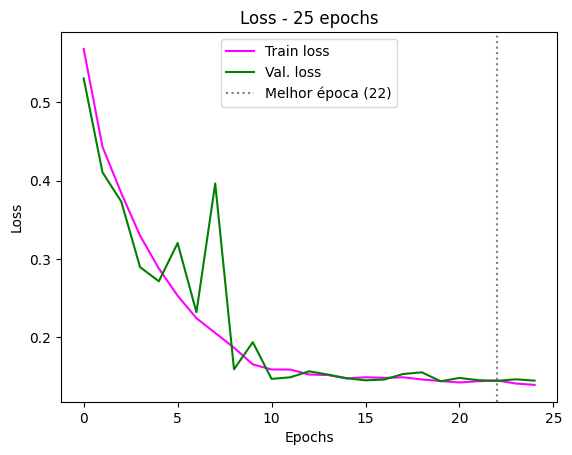

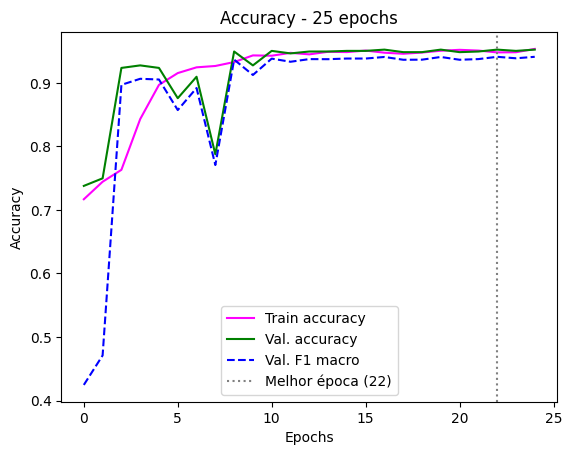

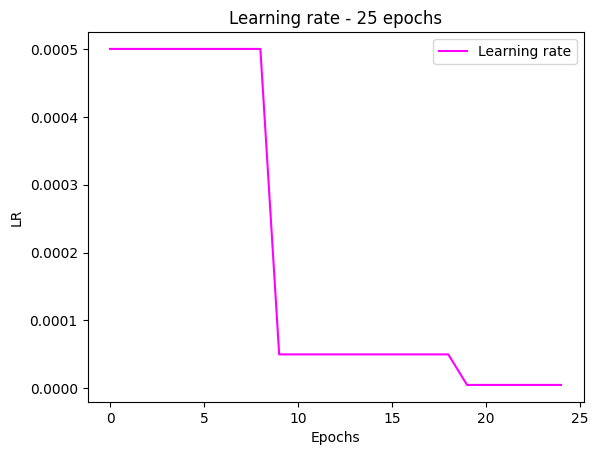

In [41]:
# Lista com os indices das épocas. [0, 1, ... num_epochs - 1]
epochs_list = []
for i in range(len(train_loss_list)):
    epochs_list.append(i)

# Plot - Loss
plt.figure()
plt.title(f'Loss - {epochs} epochs')
plt.plot(epochs_list, train_loss_list, c='magenta', ls='-', label='Train loss', fillstyle='none')
plt.plot(epochs_list, val_loss_list, c='green', ls='-', label='Val. loss', fillstyle='none')
plt.axvline(best_epoch, c='gray', ls=':', label=f'Melhor época ({best_epoch})')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(loc='best')
plt.savefig(os.path.join(EXP_PATH, 'loss_history_ResNet.pdf'))

# Plot - Accuracy
plt.figure()
plt.title(f'Accuracy - {epochs} epochs')
plt.plot(epochs_list, train_acc_list, c='magenta' ,ls='-', label='Train accuracy', fillstyle='none')
plt.plot(epochs_list, val_acc_list, c='green' ,ls='-', label='Val. accuracy', fillstyle='none')
plt.plot(epochs_list, val_f1_list, c='blue' ,ls='--', label='Val. F1 macro', fillstyle='none')
plt.axvline(best_epoch, c='gray', ls=':', label=f'Melhor época ({best_epoch})')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='best')
plt.savefig(os.path.join(EXP_PATH, 'acc_history_ResNet.pdf'))

# Plot - LR
plt.figure()
plt.title(f'Learning rate - {epochs} epochs')
plt.plot(epochs_list, lr_list, c='magenta' ,ls='-', label='Learning rate', fillstyle='none')
plt.xlabel('Epochs')
plt.ylabel('LR')
plt.legend(loc='best')
plt.savefig(os.path.join(EXP_PATH, 'lr_history_ResNet.pdf'))

In [42]:
# Garante o modo de avaliação (dropout desligado, BatchNorm com estatísticas fixas)
model.eval()

# Lista com as classes reais e classes preditas
true_test_list = []
pred_test_list = []
# Lista com as probabilidades
prob_test_list = []

# Iterate along the batches of the TEST SET
for i, (img_list, label_list) in enumerate(test_dataloader):

    if DEVICE.type == 'cuda':
        img_list = img_list.to(DEVICE)
        label_list = label_list.to(DEVICE)

    # Desabilita o cálculo do gradiente durante validação e testes.
    torch.set_grad_enabled(False)

    # -----> FORWARD
    # Saída do modelo
    outputs = model(img_list)

    # Predição
    preds = torch.argmax(outputs, dim=1)

    # Calcula probabilidades
    # https://discuss.pytorch.org/t/obtain-probabilities-from-cross-entropy-loss/157259
    outputs_prob = nn.functional.softmax(outputs, dim=1)
    ### prob_test_batch = np.asarray(outputs_prob.cpu())
    prob_test_batch = list(outputs_prob.cpu())

    # Classes reais (true) e classes preditas (pred) para este lote.
    if DEVICE.type == 'cuda':
        true_test_batch = list(label_list.cpu())
        pred_test_batch = list(preds.cpu())
    else:
        true_test_batch = list(label_list)
        pred_test_batch = list(preds)

    # Append batch results to the lists
    true_test_list += true_test_batch
    pred_test_list += pred_test_batch

    prob_test_list += prob_test_batch


Confusion matrix (test set)
[[188  46]
 [ 11 379]]

Class. report (test set)
              precision    recall  f1-score   support

      normal     0.9447    0.8034    0.8684       234
   pneumonia     0.8918    0.9718    0.9301       390

    accuracy                         0.9087       624
   macro avg     0.9182    0.8876    0.8992       624
weighted avg     0.9116    0.9087    0.9069       624



Test Acc.: 0.9087


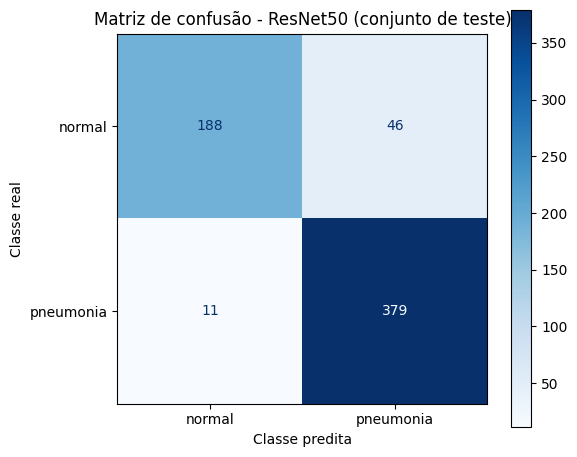

In [43]:
# Confusion matrix
conf_mat_test = metrics.confusion_matrix(true_test_list, pred_test_list)
print('\nConfusion matrix (test set)')
print(conf_mat_test)

# Classification report - Scikit-learn
class_rep_test = metrics.classification_report(true_test_list,
                                               pred_test_list,
                                               target_names=class_names,
                                               digits=4,
                                               zero_division=0)
print('\nClass. report (test set)')
print(class_rep_test)

# Accuracy
acc_test = metrics.accuracy_score(true_test_list, pred_test_list)
print('\n\nTest Acc.: {:.4f}'.format(acc_test))

# Imagem da matriz de confusão - Scikit-learn
fig, ax = plt.subplots(figsize=(6, 5))
disp = metrics.ConfusionMatrixDisplay(confusion_matrix=conf_mat_test,
                                      display_labels=class_names)
disp.plot(ax=ax, cmap='Blues', values_format='d', colorbar=True)
ax.set_title('Matriz de confusão - ResNet50 (conjunto de teste)')
ax.set_xlabel('Classe predita')
ax.set_ylabel('Classe real')
plt.tight_layout()
plt.savefig(os.path.join(EXP_PATH, 'confusion_matrix_ResNet50_test.png'), dpi=300)
plt.show()

AUC (teste) - ResNet50: 0.9523


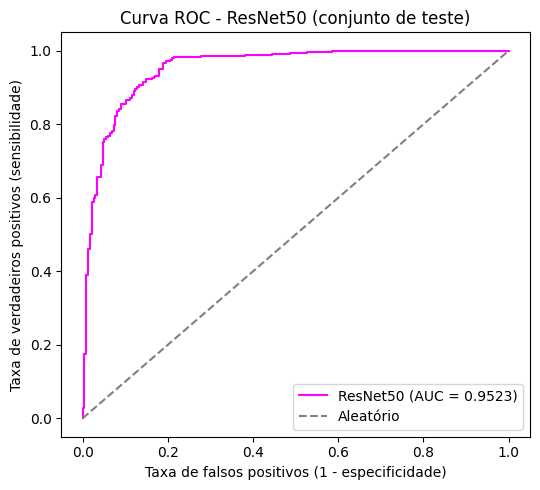

In [44]:
# Curva ROC e AUC (classe positiva = pneumonia)
y_true_roc = np.array([int(t) for t in true_test_list])
y_score_roc = np.array([float(p[1]) for p in prob_test_list])  # probabilidade de pneumonia

fpr, tpr, _ = metrics.roc_curve(y_true_roc, y_score_roc)
auc_test = metrics.roc_auc_score(y_true_roc, y_score_roc)
print(f'AUC (teste) - ResNet50: {auc_test:.4f}')

# Guarda a curva para o gráfico comparativo no final
roc_data = {}
roc_data['ResNet50'] = (fpr, tpr, auc_test)

plt.figure(figsize=(5.5, 5))
plt.plot(fpr, tpr, c='magenta', label=f'ResNet50 (AUC = {auc_test:.4f})')
plt.plot([0, 1], [0, 1], c='gray', ls='--', label='Aleatório')
plt.xlabel('Taxa de falsos positivos (1 - especificidade)')
plt.ylabel('Taxa de verdadeiros positivos (sensibilidade)')
plt.title('Curva ROC - ResNet50 (conjunto de teste)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(EXP_PATH, 'roc_ResNet50_test.png'), dpi=300)
plt.show()

In [45]:
class_rep_path = os.path.join(EXP_PATH, 'classification_report_ResNet_test.txt')
file_rep = open(class_rep_path, 'w')

file_rep.write('\nTEST. SET:')
file_rep.write('\n\nConfusion matrix:\n')
file_rep.write(str(conf_mat_test))
file_rep.write('\n\nClassification report:\n')
file_rep.write(class_rep_test)
file_rep.write('\n\nAccuracy:\t' + str(acc_test))

file_rep.close()

In [46]:
# Conjunto de testes
# Caminhos das imagens (mesma ordem do test_dataloader, pois shuffle=False)
path_test_list = [path for path, _ in test_dataset.samples]

class_rep_path = os.path.join(EXP_PATH, 'class_report_detailed_ResNet_test.csv')
file_rep = open(class_rep_path, 'w')

print('\n#\tImage path\tTarget\tPrediction\tCorrect?', end='')
file_rep.write('#;Image path;Target;Prediction;Correct?')

for class_name in class_names:
    print(f'\t {class_name}', end='')
    file_rep.write(f';{class_name}')

for i, (path, true, pred, probs) in enumerate(zip(path_test_list, true_test_list, pred_test_list, prob_test_list)):
    true = int(true)
    pred = int(pred)
    print(f'\n{i} \t {path} \t {true} \t {pred} \t {true==pred}', end='')
    file_rep.write(f'\n{i};{path};{true};{pred};{true==pred}')

    for prob in probs:
        print(f'\t{prob:.4f}', end='')
        file_rep.write(f';{prob:.4f}')

file_rep.close()



#	Image path	Target	Prediction	Correct?	 normal	 pneumonia
0 	 /content/chest_xray/test/NORMAL/IM-0001-0001.jpeg 	 0 	 0 	 True	0.8644	0.1356
1 	 /content/chest_xray/test/NORMAL/IM-0003-0001.jpeg 	 0 	 0 	 True	0.8577	0.1423
2 	 /content/chest_xray/test/NORMAL/IM-0005-0001.jpeg 	 0 	 0 	 True	0.8925	0.1075
3 	 /content/chest_xray/test/NORMAL/IM-0006-0001.jpeg 	 0 	 0 	 True	0.5073	0.4927
4 	 /content/chest_xray/test/NORMAL/IM-0007-0001.jpeg 	 0 	 0 	 True	0.9301	0.0699
5 	 /content/chest_xray/test/NORMAL/IM-0009-0001.jpeg 	 0 	 0 	 True	0.9512	0.0488
6 	 /content/chest_xray/test/NORMAL/IM-0010-0001.jpeg 	 0 	 0 	 True	0.7128	0.2872
7 	 /content/chest_xray/test/NORMAL/IM-0011-0001-0001.jpeg 	 0 	 0 	 True	0.7711	0.2289
8 	 /content/chest_xray/test/NORMAL/IM-0011-0001-0002.jpeg 	 0 	 0 	 True	0.5148	0.4852
9 	 /content/chest_xray/test/NORMAL/IM-0011-0001.jpeg 	 0 	 0 	 True	0.8960	0.1040
10 	 /content/chest_xray/test/NORMAL/IM-0013-0001.jpeg 	 0 	 0 	 True	0.8060	0.1940
11 	 /content/ch

Análise qualitativa - ResNet50

Exemplos de acertos (amostra aleatória) e dos erros mais confiantes de cada tipo: falso positivo (normal classificado como pneumonia) e falso negativo (pneumonia classificada como normal). Em verde, os acertos; em vermelho, os erros. O valor entre parênteses é a probabilidade (softmax) da classe predita.

In [47]:
# Análise qualitativa: exemplos de imagens classificadas correta e incorretamente.
# Usa as listas preenchidas na célula de teste (true_test_list, pred_test_list,
# prob_test_list) e path_test_list, todas na mesma ordem (shuffle=False).
from PIL import Image

def analise_qualitativa(model_name, n_exemplos=4, seed=SEED):
    true_arr = np.array([int(t) for t in true_test_list])
    pred_arr = np.array([int(p) for p in pred_test_list])
    prob_arr = np.array([np.asarray(p) for p in prob_test_list])
    conf_arr = prob_arr[np.arange(len(pred_arr)), pred_arr]  # confiança na classe predita

    # Grupos de interesse (classe 0 = normal, classe 1 = pneumonia)
    grupos = [
        ('Acerto - normal (VN)',            (true_arr == 0) & (pred_arr == 0)),
        ('Acerto - pneumonia (VP)',         (true_arr == 1) & (pred_arr == 1)),
        ('Erro - normal -> pneumonia (FP)', (true_arr == 0) & (pred_arr == 1)),
        ('Erro - pneumonia -> normal (FN)', (true_arr == 1) & (pred_arr == 0)),
    ]

    rng = np.random.default_rng(seed)
    fig, axes = plt.subplots(len(grupos), n_exemplos,
                             figsize=(3 * n_exemplos, 3.4 * len(grupos)))
    axes = np.atleast_2d(axes)

    for row, (titulo, mask) in enumerate(grupos):
        idx = np.where(mask)[0]
        if titulo.startswith('Erro'):
            # Erros: mostra os mais "confiantes" (os mais graves)
            idx = idx[np.argsort(-conf_arr[idx])][:n_exemplos]
        else:
            # Acertos: amostra aleatória (com semente fixa)
            idx = rng.choice(idx, size=min(n_exemplos, len(idx)), replace=False)

        for col in range(n_exemplos):
            ax = axes[row, col]
            ax.axis('off')
            if col >= len(idx):
                continue
            i = idx[col]
            img = Image.open(path_test_list[i]).convert('L')
            ax.imshow(img, cmap='gray')
            cor = 'green' if true_arr[i] == pred_arr[i] else 'red'
            ax.set_title(f'Real: {class_names[true_arr[i]]}\n'
                         f'Pred: {class_names[pred_arr[i]]} ({conf_arr[i]:.2f})\n'
                         f'{os.path.basename(path_test_list[i])}',
                         fontsize=8, color=cor)
        axes[row, 0].text(-0.08, 0.5, f'{titulo}\n(n = {mask.sum()})',
                          transform=axes[row, 0].transAxes, rotation=90,
                          ha='right', va='center', fontsize=10, fontweight='bold')

    fig.suptitle(f'Análise qualitativa - {model_name} (conjunto de teste)', fontsize=13)
    plt.tight_layout()
    plt.savefig(os.path.join(EXP_PATH, f'qualitative_{model_name}_test.png'),
                dpi=200, bbox_inches='tight')
    plt.show()

    # Resumo numérico dos erros (ajuda a discutir as causas no artigo)
    print(f'\nResumo dos erros - {model_name}')
    for titulo, mask in grupos[2:]:
        if mask.sum() > 0:
            print(f'  {titulo}: {mask.sum()} imagens | confiança média: {conf_arr[mask].mean():.3f} | '
                  f'erros com confiança > 0.90: {(conf_arr[mask] > 0.90).sum()}')
        else:
            print(f'  {titulo}: 0 imagens')
    acertos = true_arr == pred_arr
    print(f'  Confiança média nos acertos: {conf_arr[acertos].mean():.3f}')

    # Lista completa dos erros em CSV (para escolher exemplos para o artigo)
    erros = np.where(~acertos)[0]
    df_erros = pd.DataFrame({
        'idx': erros,
        'imagem': [os.path.basename(path_test_list[i]) for i in erros],
        'real': [class_names[true_arr[i]] for i in erros],
        'predito': [class_names[pred_arr[i]] for i in erros],
        'confianca': conf_arr[erros].round(4),
    }).sort_values('confianca', ascending=False)
    df_erros.to_csv(os.path.join(EXP_PATH, f'errors_{model_name}_test.csv'), sep=';', index=False)
    return df_erros


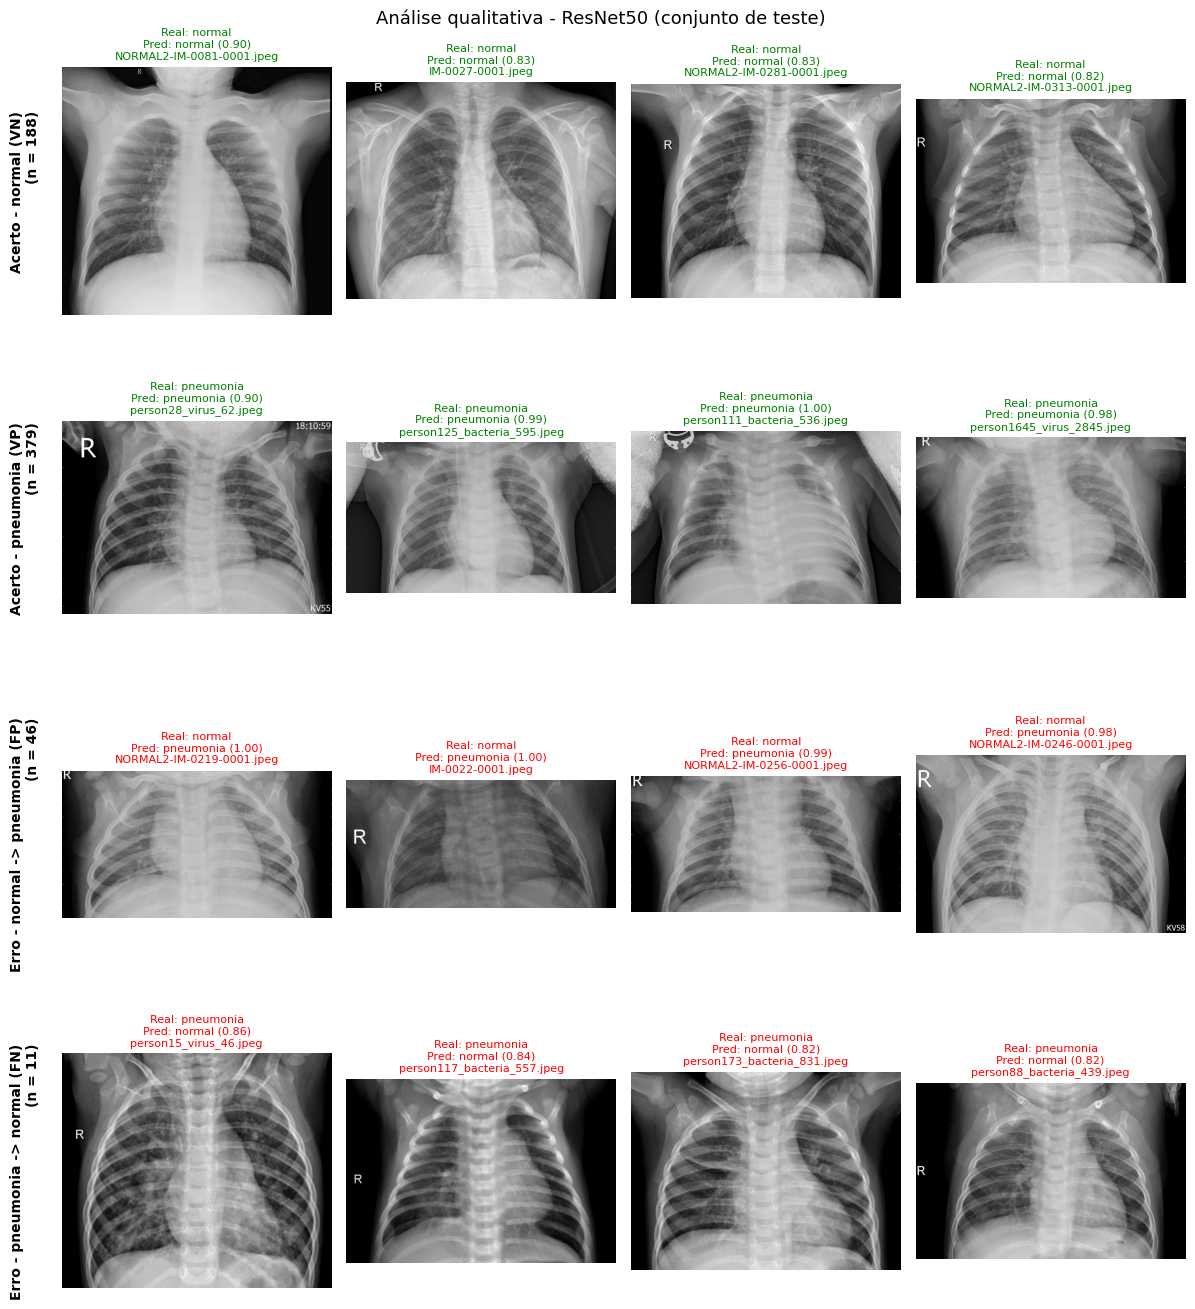


Resumo dos erros - ResNet50
  Erro - normal -> pneumonia (FP): 46 imagens | confiança média: 0.790 | erros com confiança > 0.90: 13
  Erro - pneumonia -> normal (FN): 11 imagens | confiança média: 0.695 | erros com confiança > 0.90: 0
  Confiança média nos acertos: 0.897


,idx,imagem,real,predito,confianca
18,129,NORMAL2-IM-0219-0001.jpeg,normal,pneumonia,0.9988
2,16,IM-0022-0001.jpeg,normal,pneumonia,0.9958
31,144,NORMAL2-IM-0256-0001.jpeg,normal,pneumonia,0.9887
27,140,NORMAL2-IM-0246-0001.jpeg,normal,pneumonia,0.9843
32,145,NORMAL2-IM-0259-0001.jpeg,normal,pneumonia,0.9793
23,134,NORMAL2-IM-0233-0001.jpeg,normal,pneumonia,0.9658
13,122,NORMAL2-IM-0199-0001.jpeg,normal,pneumonia,0.9635
12,121,NORMAL2-IM-0198-0001.jpeg,normal,pneumonia,0.9615
36,166,NORMAL2-IM-0292-0001.jpeg,normal,pneumonia,0.9415
25,136,NORMAL2-IM-0238-0001.jpeg,normal,pneumonia,0.9403


In [48]:
df_erros_resnet = analise_qualitativa('ResNet50', n_exemplos=4)
df_erros_resnet.head(10)

Custo computacional - ResNet50

In [49]:
# Custo computacional - ResNet50

# O dicionário 'results' guarda os resultados dos modelos para a comparação final.
results = {}

# Número de parâmetros
num_params = sum(p.numel() for p in model.parameters())
print(f'Parâmetros: {num_params / 1e6:.2f} M')

# Tamanho do arquivo do modelo salvo
model_size = os.path.getsize(os.path.join(EXP_PATH, 'model_ResNet.pth')) / (1024 ** 2)
print(f'Tamanho do modelo salvo: {model_size:.2f} MB')

# Tempo médio de treinamento por época (treinamento e validação)
time_epoch_mean = time_total_train / epochs
print(f'Tempo médio por época: {time_epoch_mean:.2f} s')

# Tempo de inferência por imagem (lote com 1 imagem)
# As primeiras execuções são de aquecimento e não entram na medida.
model.eval()
dummy_input = torch.randn(1, 3, 224, 224)
n_warmup = 10
n_runs = 50

# Inferência na GPU
time_gpu = float('nan')
if DEVICE.type == 'cuda':
    x = dummy_input.to(DEVICE)
    with torch.no_grad():
        for _ in range(n_warmup):
            model(x)
        torch.cuda.synchronize()
        t0 = time.time()
        for _ in range(n_runs):
            model(x)
        torch.cuda.synchronize()
    time_gpu = (time.time() - t0) / n_runs * 1000
    print(f'Inferência na GPU: {time_gpu:.2f} ms/imagem')

# Inferência na CPU
model.cpu()
with torch.no_grad():
    for _ in range(n_warmup):
        model(dummy_input)
    t0 = time.time()
    for _ in range(n_runs):
        model(dummy_input)
time_cpu = (time.time() - t0) / n_runs * 1000
print(f'Inferência na CPU: {time_cpu:.2f} ms/imagem')

# Devolve o modelo para a GPU
model.to(DEVICE)

# Métricas no conjunto de teste (classe 1 = pneumonia é a classe positiva)
y_true = np.array([int(t) for t in true_test_list])
y_pred = np.array([int(p) for p in pred_test_list])

acc = metrics.accuracy_score(y_true, y_pred)
prec, rec, f1, _ = metrics.precision_recall_fscore_support(y_true, y_pred, labels=[1], zero_division=0)
f1_macro = metrics.f1_score(y_true, y_pred, average='macro', zero_division=0)

# Guarda os resultados deste modelo para a comparação final
results['ResNet50'] = {
    'Acurácia': acc,
    'Precisão (pneumonia)': prec[0],
    'Recall (pneumonia)': rec[0],
    'F1 (pneumonia)': f1[0],
    'F1 macro': f1_macro,
    'AUC': auc_test,
    'Melhor época': best_epoch,
    'Parâmetros (M)': num_params / 1e6,
    'Tamanho (MB)': model_size,
    'Tempo por época (s)': time_epoch_mean,
    'Inferência GPU (ms)': time_gpu,
    'Inferência CPU (ms)': time_cpu,
}

Parâmetros: 23.51 M
Tamanho do modelo salvo: 90.00 MB
Tempo médio por época: 109.77 s
Inferência na GPU: 7.00 ms/imagem
Inferência na CPU: 147.10 ms/imagem


Treinando MobileNet

In [50]:
# Fine-tuning
model_ft = models.mobilenet_v3_large(weights=models.MobileNet_V3_Large_Weights.IMAGENET1K_V2)

num_ftrs = model_ft.classifier[3].in_features
model_ft.classifier[3] = nn.Linear(num_ftrs, num_classes)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 130MB/s]


In [51]:
model = model_ft

In [52]:
if DEVICE.type == 'cuda':
    model = model.cuda() # Cuda

# Imprime o modelo
print(str(model))

MobileNetV3(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
      (2): Hardswish()
    )
    (1): InvertedResidual(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
          (2): ReLU(inplace=True)
        )
        (1): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
        )
      )
    )
    (2): InvertedResidual(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 64, kern

In [53]:
# Função de perda
criterion = nn.CrossEntropyLoss(weight=class_weights)  # pesos por classe (None = sem pesos)

# Otimizador
optimizer = optim.SGD(model.parameters(), lr=lr, momentum=mm)

# Adjust learning rate
scheduler = lr_scheduler.StepLR(optimizer, step_size=ss)

In [54]:
# Tempo total do treinamento (treinamento e validação)
time_total_start = time.time()

# Lista das perdas (loss) e acurácias (accuracy) de trino para cada época.
train_loss_list = []
train_acc_list = []

# Lista das perdas (loss) e acurácias (accuracy) de validação para cada época.
val_loss_list = []
val_acc_list = []
# F1 macro de validação (mais informativo que a acurácia com classes desbalanceadas)
val_f1_list = []

# Melhor modelo pela VALIDAÇÃO: maior F1 macro; em caso de empate, menor perda.
# O conjunto de teste não participa desta escolha.
best_val_f1 = -1.0
best_val_loss = float('inf')
best_epoch = -1
best_state = None

# Learning rate list
lr_list = []

for epoch in range(epochs):
    # TREINAMENTO
    # =========================================================================
    # Inicia contagem de tempo da época
    time_epoch_start = time.time()

    # Habilita o modelo para o modo de treino
    model.train()

    # Perda (loss) nesta época
    loss_epoch_train = 0.0
    # Amostras classificadas corretamente nesta época
    hits_epoch_train = 0

    # Iterate along the batches of the TRAINING SET
    for inputs, labels, *_ in train_dataloader:

        if DEVICE.type == 'cuda':
            inputs = inputs.to(DEVICE)
            labels = labels.to(DEVICE)

        # Zera os parametros do gradiente
        optimizer.zero_grad()

        # FORWARD
        # ------>
        # Habilita cálculo do gradiente
        torch.set_grad_enabled(True)

        # Saída do modelo para o lote
        outputs = model(inputs)

        #  Tomar o maior valor de 'outputs' como predição.
        preds = torch.argmax(outputs, dim=1).float()

        # Calcula a perda (loss)
        loss = criterion(outputs, labels)

        # BACKWARD
        # <-------
        loss.backward()

        # Atualiza os parâmetros da rede
        optimizer.step()

        # Atualiza a perda da época
        loss_epoch_train += float(loss.item()) * inputs.size(0)

        # Atualiza o número de amostras classificadas corretamente na época.
        hits_epoch_train += torch.sum(preds == labels.data)

    # Perda desta época
    train_loss = loss_epoch_train / train_size
    # Acurácia desta época
    train_acc = float(hits_epoch_train.double() / train_size)

    # Store loss and accuracy in lists
    train_loss_list.append(train_loss)
    train_acc_list.append(train_acc)

    # VALIDAÇÃO
    # =========================================================================
    model.eval()

    # Epoch validation loss
    loss_epoch_val = 0.0 #
    # Num hits for this epoch
    hits_epoch_val = 0
    # Classes reais e preditas da validação (para o F1 macro)
    val_true_epoch = []
    val_pred_epoch = []

    # Iterate along the batches of the VALIDATION SET
    for inputs, labels, *_ in val_dataloader:

        if DEVICE.type == 'cuda':
            inputs = inputs.to(DEVICE)
            labels = labels.to(DEVICE)

        # Desabilita o cálculo do gradiente durante a validação.
        torch.set_grad_enabled(False)

        # Gero um tensor cujas linhas representam o tamanho do "batch" do input
        outputs = model(inputs)

        # Retorna o maior valor como predição.
        preds = torch.argmax(outputs, dim=1).float()

        # Calcula a perda (loss)
        loss = criterion(outputs, labels)

        # Atualiza a perda da época
        loss_epoch_val += float(loss.item()) * inputs.size(0)
        # Atualiza os acertos da época
        hits_epoch_val += torch.sum(preds == labels.data)
        val_true_epoch += labels.cpu().tolist()
        val_pred_epoch += preds.long().cpu().tolist()

    # Ajusta o learning rate
    scheduler.step()

    # Store the learning rate
    lr_epoch = optimizer.param_groups[0]['lr']
    lr_list.append(lr_epoch)

    # Perda e acuracia do conjunto de validacao para esta época
    val_loss = loss_epoch_val / val_size
    val_acc = float(hits_epoch_val.double() / val_size)
    val_f1 = metrics.f1_score(val_true_epoch, val_pred_epoch, average='macro', zero_division=0)

    # Store val loss and accuracy in lists
    val_loss_list.append(val_loss)
    val_acc_list.append(val_acc)
    val_f1_list.append(val_f1)

    # Guarda os pesos da melhor época (cópia em memória)
    is_best = (val_f1 > best_val_f1) or (val_f1 == best_val_f1 and val_loss < best_val_loss)
    if is_best:
        best_val_f1 = val_f1
        best_val_loss = val_loss
        best_epoch = epoch
        best_state = copy.deepcopy(model.state_dict())

    # Tempo total desta época
    time_epoch = time.time() - time_epoch_start

    # PRINTING
    # --------
    print(f'Epoch {epoch}/{ epochs - 1} - TRAIN Loss: {train_loss:.4f} TRAIN Acc: {train_acc:.4f} - VAL. Loss: {val_loss:.4f} VAL. Acc: {val_acc:.4f} VAL. F1 macro: {val_f1:.4f}{" *" if is_best else ""} ({time_epoch:.4f} seconds)')

# Tempo total do treinamento
time_total_train = time.time() - time_total_start

# PRINTING
print(f'\nTreinamento finalizado. ({int(time_total_train // 60)}m and {int(time_total_train % 60)}s)')

# Restaura os pesos da melhor época (escolhida pela validação) para o teste
model.load_state_dict(best_state)
model.eval()
print(f'Melhor época: {best_epoch} (VAL. F1 macro: {best_val_f1:.4f} | VAL. Loss: {best_val_loss:.4f})')

Epoch 0/24 - TRAIN Loss: 0.6342 TRAIN Acc: 0.6861 - VAL. Loss: 0.6195 VAL. Acc: 0.7478 VAL. F1 macro: 0.6023 * (96.5717 seconds)
Epoch 1/24 - TRAIN Loss: 0.4907 TRAIN Acc: 0.8427 - VAL. Loss: 0.5113 VAL. Acc: 0.8183 VAL. F1 macro: 0.6898 * (96.5329 seconds)
Epoch 2/24 - TRAIN Loss: 0.3895 TRAIN Acc: 0.8812 - VAL. Loss: 0.4338 VAL. Acc: 0.8808 VAL. F1 macro: 0.8195 * (96.7052 seconds)
Epoch 3/24 - TRAIN Loss: 0.3192 TRAIN Acc: 0.9021 - VAL. Loss: 0.3704 VAL. Acc: 0.9146 VAL. F1 macro: 0.8796 * (95.5723 seconds)
Epoch 4/24 - TRAIN Loss: 0.2594 TRAIN Acc: 0.9228 - VAL. Loss: 0.3237 VAL. Acc: 0.9345 VAL. F1 macro: 0.9117 * (98.8960 seconds)
Epoch 5/24 - TRAIN Loss: 0.2252 TRAIN Acc: 0.9271 - VAL. Loss: 0.2766 VAL. Acc: 0.9454 VAL. F1 macro: 0.9269 * (97.2430 seconds)
Epoch 6/24 - TRAIN Loss: 0.1970 TRAIN Acc: 0.9311 - VAL. Loss: 0.2560 VAL. Acc: 0.9384 VAL. F1 macro: 0.9166 (96.3523 seconds)
Epoch 7/24 - TRAIN Loss: 0.1780 TRAIN Acc: 0.9311 - VAL. Loss: 0.2201 VAL. Acc: 0.9464 VAL. F1 macr

In [55]:
# Salvando os pesos (state_dict) do melhor modelo
# Para carregar: model.load_state_dict(torch.load(caminho)); model.eval()
torch.save(model.state_dict(), os.path.join(EXP_PATH, 'model_MobileNetV3.pth'))

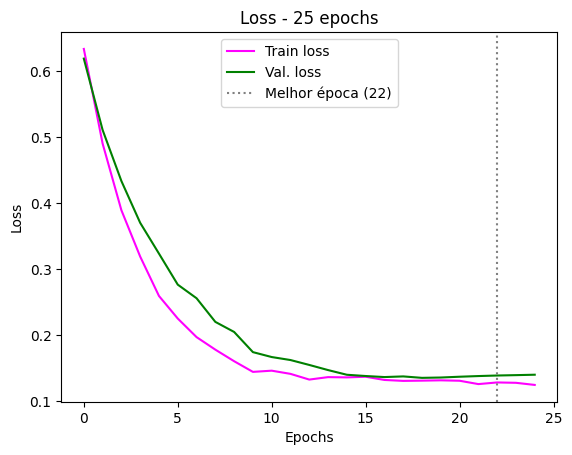

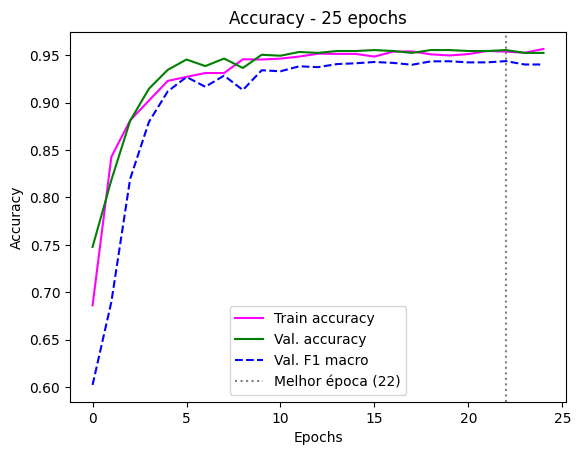

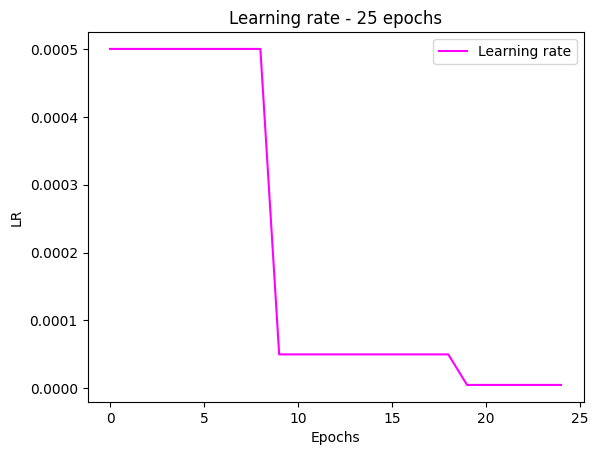

In [56]:
# Lista com os indices das épocas. [0, 1, ... num_epochs - 1]
epochs_list = []
for i in range(len(train_loss_list)):
    epochs_list.append(i)

# Plot - Loss
plt.figure()
plt.title(f'Loss - {epochs} epochs')
plt.plot(epochs_list, train_loss_list, c='magenta', ls='-', label='Train loss', fillstyle='none')
plt.plot(epochs_list, val_loss_list, c='green', ls='-', label='Val. loss', fillstyle='none')
plt.axvline(best_epoch, c='gray', ls=':', label=f'Melhor época ({best_epoch})')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(loc='best')
plt.savefig(os.path.join(EXP_PATH, 'loss_history_MobileNetV3.pdf'))

# Plot - Accuracy
plt.figure()
plt.title(f'Accuracy - {epochs} epochs')
plt.plot(epochs_list, train_acc_list, c='magenta' ,ls='-', label='Train accuracy', fillstyle='none')
plt.plot(epochs_list, val_acc_list, c='green' ,ls='-', label='Val. accuracy', fillstyle='none')
plt.plot(epochs_list, val_f1_list, c='blue' ,ls='--', label='Val. F1 macro', fillstyle='none')
plt.axvline(best_epoch, c='gray', ls=':', label=f'Melhor época ({best_epoch})')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='best')
plt.savefig(os.path.join(EXP_PATH, 'acc_history_MobileNetV3.pdf'))

# Plot - LR
plt.figure()
plt.title(f'Learning rate - {epochs} epochs')
plt.plot(epochs_list, lr_list, c='magenta' ,ls='-', label='Learning rate', fillstyle='none')
plt.xlabel('Epochs')
plt.ylabel('LR')
plt.legend(loc='best')
plt.savefig(os.path.join(EXP_PATH, 'lr_history_MobileNetV3.pdf'))

In [57]:
# Garante o modo de avaliação (dropout desligado, BatchNorm com estatísticas fixas)
model.eval()

# Lista com as classes reais e classes preditas
true_test_list = []
pred_test_list = []
# Lista com as probabilidades
prob_test_list = []

# Iterate along the batches of the TEST SET
for i, (img_list, label_list) in enumerate(test_dataloader):

    if DEVICE.type == 'cuda':
        img_list = img_list.to(DEVICE)
        label_list = label_list.to(DEVICE)

    # Desabilita o cálculo do gradiente durante validação e testes.
    torch.set_grad_enabled(False)

    # -----> FORWARD
    # Saída do modelo
    outputs = model(img_list)

    # Predição
    preds = torch.argmax(outputs, dim=1)

    # Calcula probabilidades
    # https://discuss.pytorch.org/t/obtain-probabilities-from-cross-entropy-loss/157259
    outputs_prob = nn.functional.softmax(outputs, dim=1)
    ### prob_test_batch = np.asarray(outputs_prob.cpu())
    prob_test_batch = list(outputs_prob.cpu())

    # Classes reais (true) e classes preditas (pred) para este lote.
    if DEVICE.type == 'cuda':
        true_test_batch = list(label_list.cpu())
        pred_test_batch = list(preds.cpu())
    else:
        true_test_batch = list(label_list)
        pred_test_batch = list(preds)

    # Append batch results to the lists
    true_test_list += true_test_batch
    pred_test_list += pred_test_batch

    prob_test_list += prob_test_batch


Confusion matrix (test set)
[[153  81]
 [ 13 377]]

Class. report (test set)
              precision    recall  f1-score   support

      normal     0.9217    0.6538    0.7650       234
   pneumonia     0.8231    0.9667    0.8892       390

    accuracy                         0.8494       624
   macro avg     0.8724    0.8103    0.8271       624
weighted avg     0.8601    0.8494    0.8426       624



Test Acc.: 0.8494


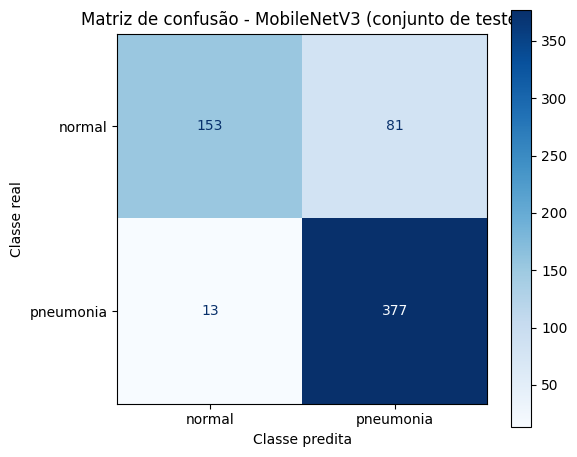

In [58]:
# Confusion matrix
conf_mat_test = metrics.confusion_matrix(true_test_list, pred_test_list)
print('\nConfusion matrix (test set)')
print(conf_mat_test)

# Classification report - Scikit-learn
class_rep_test = metrics.classification_report(true_test_list,
                                               pred_test_list,
                                               target_names=class_names,
                                               digits=4,
                                               zero_division=0)
print('\nClass. report (test set)')
print(class_rep_test)

# Accuracy
acc_test = metrics.accuracy_score(true_test_list, pred_test_list)
print('\n\nTest Acc.: {:.4f}'.format(acc_test))

# Imagem da matriz de confusão - Scikit-learn
fig, ax = plt.subplots(figsize=(6, 5))
disp = metrics.ConfusionMatrixDisplay(confusion_matrix=conf_mat_test,
                                      display_labels=class_names)
disp.plot(ax=ax, cmap='Blues', values_format='d', colorbar=True)
ax.set_title('Matriz de confusão - MobileNetV3 (conjunto de teste)')
ax.set_xlabel('Classe predita')
ax.set_ylabel('Classe real')
plt.tight_layout()
plt.savefig(os.path.join(EXP_PATH, 'confusion_matrix_MobileNetV3_test.png'), dpi=300)
plt.show()

AUC (teste) - MobileNetV3: 0.9540


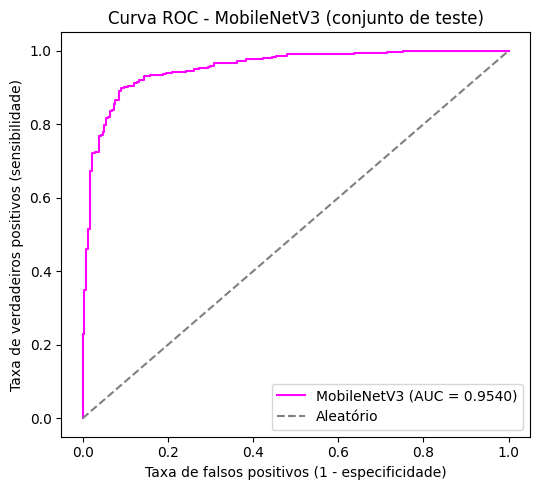

In [59]:
# Curva ROC e AUC (classe positiva = pneumonia)
y_true_roc = np.array([int(t) for t in true_test_list])
y_score_roc = np.array([float(p[1]) for p in prob_test_list])  # probabilidade de pneumonia

fpr, tpr, _ = metrics.roc_curve(y_true_roc, y_score_roc)
auc_test = metrics.roc_auc_score(y_true_roc, y_score_roc)
print(f'AUC (teste) - MobileNetV3: {auc_test:.4f}')

# Guarda a curva para o gráfico comparativo no final
if 'roc_data' not in globals():
    roc_data = {}
roc_data['MobileNetV3'] = (fpr, tpr, auc_test)

plt.figure(figsize=(5.5, 5))
plt.plot(fpr, tpr, c='magenta', label=f'MobileNetV3 (AUC = {auc_test:.4f})')
plt.plot([0, 1], [0, 1], c='gray', ls='--', label='Aleatório')
plt.xlabel('Taxa de falsos positivos (1 - especificidade)')
plt.ylabel('Taxa de verdadeiros positivos (sensibilidade)')
plt.title('Curva ROC - MobileNetV3 (conjunto de teste)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(EXP_PATH, 'roc_MobileNetV3_test.png'), dpi=300)
plt.show()

In [60]:
class_rep_path = os.path.join(EXP_PATH, 'classification_report_MobileNetV3_test.txt')
file_rep = open(class_rep_path, 'w')

file_rep.write('\nTEST. SET:')
file_rep.write('\n\nConfusion matrix:\n')
file_rep.write(str(conf_mat_test))
file_rep.write('\n\nClassification report:\n')
file_rep.write(class_rep_test)
file_rep.write('\n\nAccuracy:\t' + str(acc_test))

file_rep.close()


In [61]:
# Conjunto de testes
# Caminhos das imagens (mesma ordem do test_dataloader, pois shuffle=False)
path_test_list = [path for path, _ in test_dataset.samples]

class_rep_path = os.path.join(EXP_PATH, 'class_report_detailed_MobileNetV3_test.csv')
file_rep = open(class_rep_path, 'w')

print('\n#\tImage path\tTarget\tPrediction\tCorrect?', end='')
file_rep.write('#;Image path;Target;Prediction;Correct?')

for class_name in class_names:
    print(f'\t {class_name}', end='')
    file_rep.write(f';{class_name}')

for i, (path, true, pred, probs) in enumerate(zip(path_test_list, true_test_list, pred_test_list, prob_test_list)):
    true = int(true)
    pred = int(pred)
    print(f'\n{i} \t {path} \t {true} \t {pred} \t {true==pred}', end='')
    file_rep.write(f'\n{i};{path};{true};{pred};{true==pred}')

    for prob in probs:
        print(f'\t{prob:.4f}', end='')
        file_rep.write(f';{prob:.4f}')

file_rep.close()



#	Image path	Target	Prediction	Correct?	 normal	 pneumonia
0 	 /content/chest_xray/test/NORMAL/IM-0001-0001.jpeg 	 0 	 1 	 False	0.4836	0.5164
1 	 /content/chest_xray/test/NORMAL/IM-0003-0001.jpeg 	 0 	 0 	 True	0.7282	0.2718
2 	 /content/chest_xray/test/NORMAL/IM-0005-0001.jpeg 	 0 	 0 	 True	0.6989	0.3011
3 	 /content/chest_xray/test/NORMAL/IM-0006-0001.jpeg 	 0 	 0 	 True	0.5895	0.4105
4 	 /content/chest_xray/test/NORMAL/IM-0007-0001.jpeg 	 0 	 0 	 True	0.8719	0.1281
5 	 /content/chest_xray/test/NORMAL/IM-0009-0001.jpeg 	 0 	 0 	 True	0.9571	0.0429
6 	 /content/chest_xray/test/NORMAL/IM-0010-0001.jpeg 	 0 	 0 	 True	0.5604	0.4396
7 	 /content/chest_xray/test/NORMAL/IM-0011-0001-0001.jpeg 	 0 	 0 	 True	0.6885	0.3115
8 	 /content/chest_xray/test/NORMAL/IM-0011-0001-0002.jpeg 	 0 	 1 	 False	0.3027	0.6973
9 	 /content/chest_xray/test/NORMAL/IM-0011-0001.jpeg 	 0 	 0 	 True	0.5764	0.4236
10 	 /content/chest_xray/test/NORMAL/IM-0013-0001.jpeg 	 0 	 1 	 False	0.3548	0.6452
11 	 /content

Análise qualitativa - MobileNetV3

Exemplos de acertos (amostra aleatória) e dos erros mais confiantes de cada tipo: falso positivo (normal classificado como pneumonia) e falso negativo (pneumonia classificada como normal). Em verde, os acertos; em vermelho, os erros. O valor entre parênteses é a probabilidade (softmax) da classe predita.

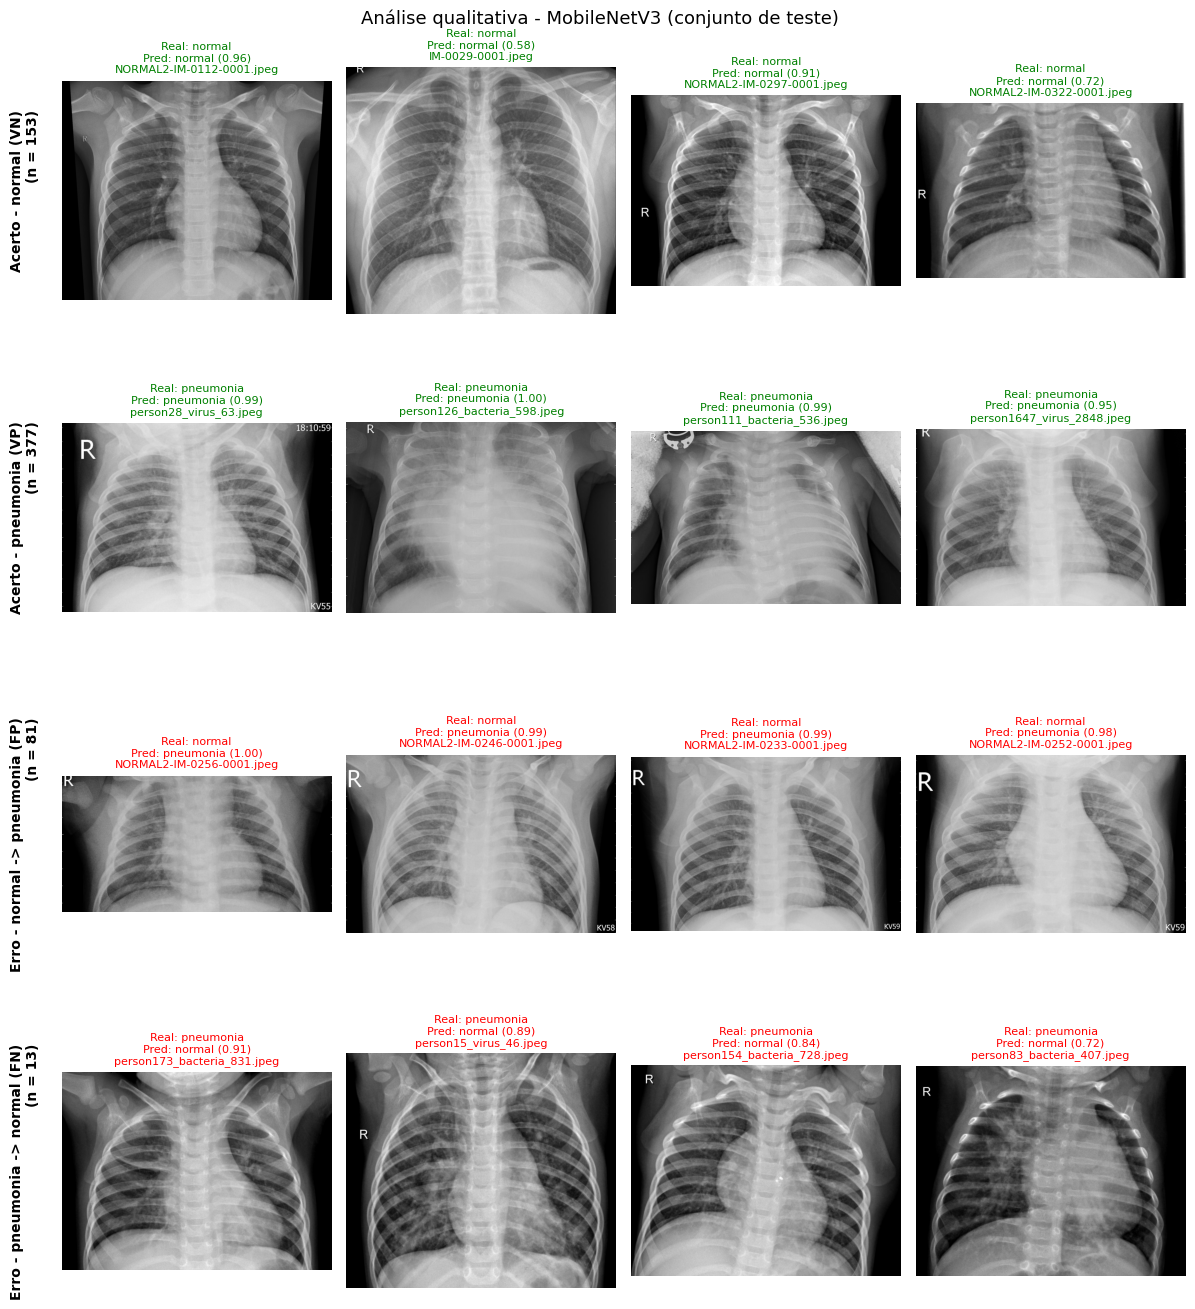


Resumo dos erros - MobileNetV3
  Erro - normal -> pneumonia (FP): 81 imagens | confiança média: 0.737 | erros com confiança > 0.90: 17
  Erro - pneumonia -> normal (FN): 13 imagens | confiança média: 0.681 | erros com confiança > 0.90: 1
  Confiança média nos acertos: 0.918


,idx,imagem,real,predito,confianca
64,144,NORMAL2-IM-0256-0001.jpeg,normal,pneumonia,0.9963
60,140,NORMAL2-IM-0246-0001.jpeg,normal,pneumonia,0.9929
54,134,NORMAL2-IM-0233-0001.jpeg,normal,pneumonia,0.9878
63,143,NORMAL2-IM-0252-0001.jpeg,normal,pneumonia,0.9840
6,16,IM-0022-0001.jpeg,normal,pneumonia,0.9722
52,132,NORMAL2-IM-0229-0001.jpeg,normal,pneumonia,0.9635
41,119,NORMAL2-IM-0195-0001.jpeg,normal,pneumonia,0.9631
53,133,NORMAL2-IM-0232-0001.jpeg,normal,pneumonia,0.9626
65,145,NORMAL2-IM-0259-0001.jpeg,normal,pneumonia,0.9609
75,209,NORMAL2-IM-0349-0001.jpeg,normal,pneumonia,0.9459


In [62]:
df_erros_mobilenet = analise_qualitativa('MobileNetV3', n_exemplos=4)
df_erros_mobilenet.head(10)

Custo computacional - MobileNetV3

In [63]:
# Custo computacional - MobileNetV3

# Número de parâmetros
num_params = sum(p.numel() for p in model.parameters())
print(f'Parâmetros: {num_params / 1e6:.2f} M')

# Tamanho do arquivo do modelo salvo
model_size = os.path.getsize(os.path.join(EXP_PATH, 'model_MobileNetV3.pth')) / (1024 ** 2)
print(f'Tamanho do modelo salvo: {model_size:.2f} MB')

# Tempo médio de treinamento por época (treinamento e validação)
time_epoch_mean = time_total_train / epochs
print(f'Tempo médio por época: {time_epoch_mean:.2f} s')

# Tempo de inferência por imagem (lote com 1 imagem)
# As primeiras execuções são de aquecimento e não entram na medida.
model.eval()
dummy_input = torch.randn(1, 3, 224, 224)
n_warmup = 10
n_runs = 50

# Inferência na GPU
time_gpu = float('nan')
if DEVICE.type == 'cuda':
    x = dummy_input.to(DEVICE)
    with torch.no_grad():
        for _ in range(n_warmup):
            model(x)
        torch.cuda.synchronize()
        t0 = time.time()
        for _ in range(n_runs):
            model(x)
        torch.cuda.synchronize()
    time_gpu = (time.time() - t0) / n_runs * 1000
    print(f'Inferência na GPU: {time_gpu:.2f} ms/imagem')

# Inferência na CPU
model.cpu()
with torch.no_grad():
    for _ in range(n_warmup):
        model(dummy_input)
    t0 = time.time()
    for _ in range(n_runs):
        model(dummy_input)
time_cpu = (time.time() - t0) / n_runs * 1000
print(f'Inferência na CPU: {time_cpu:.2f} ms/imagem')

# Devolve o modelo para a GPU
model.to(DEVICE)

# Métricas no conjunto de teste (classe 1 = pneumonia é a classe positiva)
y_true = np.array([int(t) for t in true_test_list])
y_pred = np.array([int(p) for p in pred_test_list])

acc = metrics.accuracy_score(y_true, y_pred)
prec, rec, f1, _ = metrics.precision_recall_fscore_support(y_true, y_pred, labels=[1], zero_division=0)
f1_macro = metrics.f1_score(y_true, y_pred, average='macro', zero_division=0)

# Guarda os resultados deste modelo para a comparação final
results['MobileNetV3-Large'] = {
    'Acurácia': acc,
    'Precisão (pneumonia)': prec[0],
    'Recall (pneumonia)': rec[0],
    'F1 (pneumonia)': f1[0],
    'F1 macro': f1_macro,
    'AUC': auc_test,
    'Melhor época': best_epoch,
    'Parâmetros (M)': num_params / 1e6,
    'Tamanho (MB)': model_size,
    'Tempo por época (s)': time_epoch_mean,
    'Inferência GPU (ms)': time_gpu,
    'Inferência CPU (ms)': time_cpu,
}

Parâmetros: 4.20 M
Tamanho do modelo salvo: 16.24 MB
Tempo médio por época: 96.77 s
Inferência na GPU: 9.09 ms/imagem
Inferência na CPU: 28.17 ms/imagem


Comparação final entre os modelos

                   Acurácia  Precisão (pneumonia)  Recall (pneumonia)  F1 (pneumonia)  F1 macro     AUC  Melhor época  Parâmetros (M)  Tamanho (MB)  Tempo por época (s)  Inferência GPU (ms)  Inferência CPU (ms)
ResNet50             0.9087                0.8918              0.9718          0.9301    0.8992  0.9523          22.0         23.5121       89.9965             109.7663               6.9983             147.1000
MobileNetV3-Large    0.8494                0.8231              0.9667          0.8892    0.8271  0.9540          22.0          4.2046       16.2382              96.7704               9.0935              28.1739

Parâmetros: o MobileNetV3 tem 5.6x menos que o ResNet50
Tamanho do modelo: o MobileNetV3 é 5.5x menor
Inferência na CPU: o MobileNetV3 é 5.2x mais rápido
Recall (pneumonia): ResNet50 0.9718 | MobileNetV3 0.9667
F1 macro: ResNet50 0.8992 | MobileNetV3 0.8271
AUC: ResNet50 0.9523 | MobileNetV3 0.9540


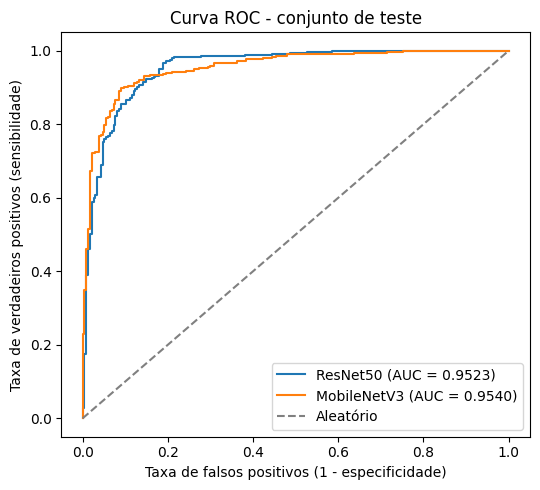

In [64]:

# Tabela comparativa entre os modelos
df_results = pd.DataFrame(results).T
print(df_results.round(4).to_string())

# Salvando a tabela
df_results.to_csv(os.path.join(EXP_PATH, 'comparison_models.csv'), sep=';')

# Resumo: o MobileNetV3 é uma alternativa viável?
r = results['ResNet50']
m = results['MobileNetV3-Large']
print(f"\nParâmetros: o MobileNetV3 tem {r['Parâmetros (M)'] / m['Parâmetros (M)']:.1f}x menos que o ResNet50")
print(f"Tamanho do modelo: o MobileNetV3 é {r['Tamanho (MB)'] / m['Tamanho (MB)']:.1f}x menor")
print(f"Inferência na CPU: o MobileNetV3 é {r['Inferência CPU (ms)'] / m['Inferência CPU (ms)']:.1f}x mais rápido")
print(f"Recall (pneumonia): ResNet50 {r['Recall (pneumonia)']:.4f} | MobileNetV3 {m['Recall (pneumonia)']:.4f}")
print(f"F1 macro: ResNet50 {r['F1 macro']:.4f} | MobileNetV3 {m['F1 macro']:.4f}")
print(f"AUC: ResNet50 {r['AUC']:.4f} | MobileNetV3 {m['AUC']:.4f}")

# Curvas ROC dos dois modelos no mesmo gráfico (para o artigo)
plt.figure(figsize=(5.5, 5))
for nome, (fpr, tpr, auc_v) in roc_data.items():
    plt.plot(fpr, tpr, label=f'{nome} (AUC = {auc_v:.4f})')
plt.plot([0, 1], [0, 1], c='gray', ls='--', label='Aleatório')
plt.xlabel('Taxa de falsos positivos (1 - especificidade)')
plt.ylabel('Taxa de verdadeiros positivos (sensibilidade)')
plt.title('Curva ROC - conjunto de teste')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(EXP_PATH, 'roc_comparison_test.png'), dpi=300)
plt.show()